# Lab 02: Classical Machine Learning Pipeline
**Problem:** Predict whether a telecom customer will churn (Telco Customer Churn dataset).

**Author:** Arandela, Jherrymei D.

**Goal:** Build a supervised pipeline with **no data leakage** and compare classifiers using
accuracy, precision, recall and F1.

**Leakage rules followed in this notebook**
1. Split into train/test *before* any fitting.
2. Imputation, scaling and encoding live inside a scikit-learn `Pipeline`,
   so they are re-fit on the training part of every CV fold only.
3. The test set is used once, at the end.
4. `customerID` is dropped (identifier, no predictive meaning).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # download from Kaggle, place in Lab02/
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

## 1. Load and inspect data

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges is stored as text with blank strings -> convert (blanks become NaN, imputed later in the pipeline)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.drop(columns=["customerID"])

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn"])

print("Missing values:\n", X.isna().sum()[X.isna().sum() > 0])
print("\nClass balance:\n", y.value_counts(normalize=True).round(3))

Missing values:
 TotalCharges    11
dtype: int64

Class balance:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


**Observation:** Churners are the minority class (~27%). A model that always predicts "no churn"
gets ~73% accuracy, so accuracy alone is misleading. We therefore also report precision, recall and F1.

## 2. Train/test split (done BEFORE any fitting)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


## 3. Preprocessing inside a Pipeline

In [5]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
pipelines = {name: Pipeline([("prep", preprocess), ("clf", m)]) for name, m in models.items()}

## 4. Cross-validation on the training set (preprocessing re-fit inside every fold)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1"]

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for m in scoring:
        s = scores[f"test_{m}"]
        row[m.capitalize()] = f"{s.mean():.3f} ± {s.std():.3f}"
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table

,Accuracy,Precision,Recall,F1
Model,,,,
Dummy (majority),0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic Regression,0.749 ± 0.015,0.517 ± 0.019,0.801 ± 0.038,0.629 ± 0.023
Random Forest,0.769 ± 0.008,0.548 ± 0.011,0.747 ± 0.027,0.632 ± 0.015
Gradient Boosting,0.803 ± 0.011,0.661 ± 0.028,0.534 ± 0.023,0.590 ± 0.022


## 5. Final evaluation on the held-out test set (used once)

In [7]:
test_rows, fitted = [], {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

summary = pd.DataFrame(test_rows).set_index("Model").round(3)
summary.to_csv(RESULTS_DIR / "summary_comparison.csv")
cv_table.to_csv(RESULTS_DIR / "cv_comparison.csv")
summary

,Accuracy,Precision,Recall,F1
Model,,,,
Dummy (majority),0.735,0.000,0.000,0.000
Logistic Regression,0.737,0.503,0.783,0.613
Random Forest,0.768,0.546,0.746,0.631
Gradient Boosting,0.806,0.674,0.524,0.589


## 6. Confusion matrices

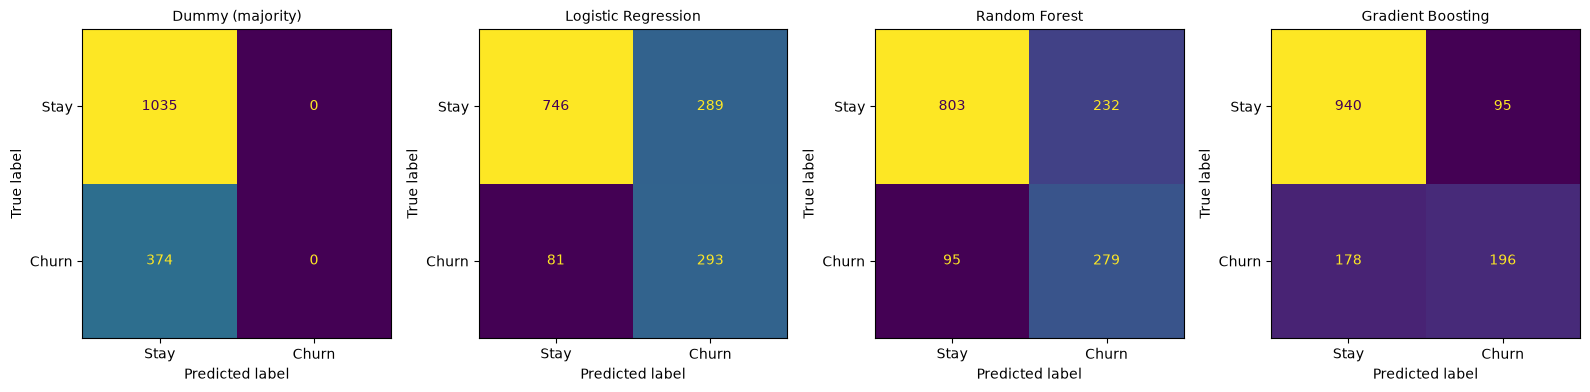

In [8]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["Stay", "Churn"])
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 7. Demonstration: what data leakage looks like
Here we scale the **whole** dataset before splitting (the wrong way). The statistics of the
test rows leak into training. The effect is often small on this dataset, but the practice is
wrong, and on smaller or noisier data it inflates results.

In [9]:
num_all = SimpleImputer(strategy="median").fit_transform(X[numeric_cols])   # LEAKY: fit on all rows
num_all = StandardScaler().fit_transform(num_all)                           # LEAKY: fit on all rows
X_leaky = pd.concat([pd.DataFrame(num_all, columns=numeric_cols, index=X.index),
                     pd.get_dummies(X[categorical_cols])], axis=1)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_leaky, y, test_size=0.2, stratify=y, random_state=SEED)
leaky_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(Xl_tr, yl_tr)
leaky_f1 = f1_score(yl_te, leaky_model.predict(Xl_te))
correct_f1 = summary.loc["Logistic Regression", "F1"]
print(f"Leaky F1: {leaky_f1:.3f} | Correct pipeline F1: {correct_f1:.3f}")

Leaky F1: 0.613 | Correct pipeline F1: 0.613


The leaky and correct pipelines gave the same F1 (0.613). Scaling uses only three numeric columns on a large dataset, so the test rows barely change the mean and standard deviation. The leak is still bad practice and can inflate results on smaller or messier datasets, which is why we keep all preprocessing inside the pipeline.

## 8. Discussion 
- **Best model overall:** Random Forest had the best F1 (0.631), balancing precision (0.546) and recall (0.746). Logistic Regression had the highest recall (0.783), and Gradient Boosting had the highest accuracy (0.806) but the lowest recall (0.524). Since missing a churner costs more than a false alarm, we consider Random Forest the best overall choice, with Logistic Regression a good option if catching as many churners as possible is the priority.
- **Accuracy vs. recall:** The Dummy baseline has high accuracy but zero recall, so it is useless.
- **Business trade-off:** Missing a churner (false negative) costs more than a wasted retention offer
  (false positive), so recall and F1 matter more than raw accuracy here.
- **Limitations:** Single train/test split, no hyperparameter tuning, no probability calibration or threshold tuning.
- **Next steps:** GridSearchCV inside the pipeline, threshold tuning, feature importance analysis.